# MLT Assignment #3: Bioresponse, logistic regression as a neural network (GD, SGD, Adam)

Mironov Kirill, group J4132

Data: `bioresponse.csv`. Each row is a molecule, `Activity` is the target (1 if the molecule caused a biological response, 0 if not), `D1 ... D1776` are molecular descriptors.

What is done:
1. Logistic regression trained with classic gradient descent (GD), 75% train, 25% test.
2. `optimize()` changed to stochastic gradient descent (SGD).
3. Adam in numpy and a comparison of GD, SGD and Adam.
4. Learning curves (loss vs iteration) for the three optimizers.
5. 5 learning rates for each optimizer: learning curves and accuracy.
6. Conclusions.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings('ignore', category=RuntimeWarning)

RANDOM_STATE = 42
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

## 1. Data

In [2]:
df = pd.read_csv('bioresponse.csv')
features = df.drop(columns='Activity')
print('shape:', df.shape)
print('NaN values:', df.isna().sum().sum())
print('feature range: [%.1f, %.1f]' % (features.values.min(), features.values.max()))
print('binary features (only 0 and 1):', features.isin([0, 1]).all().sum())
print(df['Activity'].value_counts(normalize=True).rename('share').round(3))

shape: (3751, 1777)
NaN values: 0
feature range: [0.0, 1.0]
binary features (only 0 and 1): 834
Activity
1    0.542
0    0.458
Name: share, dtype: float64


No missing values. All descriptors are already in [0, 1], 834 of 1776 are binary, so I don't scale them. 54% of the molecules are active, so accuracy is fine as the main metric. I also look at log-loss, because this is what the optimizers minimize.

In [3]:
X = features.values
y = df['Activity'].values
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

# objects are in columns: X has shape (n_features, m), Y has shape (1, m)
train_set_x, test_set_x = X_tr.T.copy(), X_te.T.copy()
train_set_y, test_set_y = y_tr.reshape(1, -1).astype(float), y_te.reshape(1, -1).astype(float)
m_train = train_set_x.shape[1]
print('train_set_x:', train_set_x.shape, ' test_set_x:', test_set_x.shape)
print('share of 1 in train / test: %.3f / %.3f' % (train_set_y.mean(), test_set_y.mean()))

train_set_x: (1776, 2813)  test_set_x: (1776, 938)
share of 1 in train / test: 0.542 / 0.543


Split 75 / 25 with stratification and the same `random_state` as in Task 1. The test part is only used for the final numbers and the test loss curves.

## 2. Functions and fixes

I kept the functions and their names (`sigmoid`, `initialize_with_zeros`, `propagate`, `optimize`, `predict`, `model`), but on this dataset the code doesn't work as is, so I fixed a few things:

1. `initialize_with_zeros` actually takes `w` from N(0, 1). With 1776 features in [0, 1], z = wᵀx is around ±8, the sigmoid is saturated from the start, for some objects A is exactly 1.0, and `cost = nan` on the first iteration (checked in the cell below). The loss is convex, so starting from zeros is fine, and then all optimizers start from the same point.
2. `1 / (1 + exp(-z))` overflows for large negative z. I use `exp(-logaddexp(0, -z))`, and the loss is also written with `logaddexp`, so there is no log(0).
3. `print_cost and i // 100 == 0` prints the first 100 iterations, not every 100th. It should be `%`.
4. `costs` was saved only every 100th iteration (20 points for 2000 iterations). Now for GD and full batch Adam I save the train and test loss after every update, and for SGD 20 times per epoch.
5. `model()` calls `predict(w, b, X_test)` without `threshold` and fails with TypeError. Now `threshold=0.5` by default, and `predict` is vectorized.
6. `cost` and `db` were arrays of shape (1,), so `b` became an array after the first step. Now they are floats.
7. `w -= ...` changes the array in place, so two runs from the same `w` would share it. I use `w = w - ...`.

In [4]:
np.random.seed(0)
w0 = np.random.normal(loc=0.0, scale=1.0, size=train_set_x.shape[0]).reshape(-1, 1)
z0 = np.dot(w0.T, train_set_x)
A0 = 1. / (1. + np.exp(-z0))
print(f'std of z: {z0.std():.1f}, share of objects with |z| > 5: {(np.abs(z0) > 5).mean():.2f}, '
      f'objects with A == 1.0 exactly: {(A0 == 1).sum()}')
print('cost with the original formula:', -np.mean(train_set_y * np.log(A0) + (1 - train_set_y) * np.log(1 - A0)))

std of z: 8.4, share of objects with |z| > 5: 0.68, objects with A == 1.0 exactly: 22
cost with the original formula: nan


In [5]:
def sigmoid(z):
    return np.exp(-np.logaddexp(0., -z))


def initialize_with_zeros(dim):
    w = np.zeros((dim, 1))
    b = 0.
    return w, b


def cost_function(w, b, X, Y):
    Z = np.dot(w.T, X) + b
    return float(np.mean(Y * np.logaddexp(0., -Z) + (1 - Y) * np.logaddexp(0., Z)))


def propagate(w, b, X, Y):
    m = X.shape[1]

    # forward propagation
    A = sigmoid(np.dot(w.T, X) + b)
    cost = cost_function(w, b, X, Y)

    # backward propagation
    dw = np.dot(X, (A - Y).T) / m
    db = float(np.sum(A - Y) / m)

    return {"dw": dw, "db": db}, cost


def predict(w, b, X, threshold=0.5):
    A = sigmoid(np.dot(w.T, X) + b)
    return (A > threshold).astype(float)


def accuracy(w, b, X, Y):
    return float(np.mean(predict(w, b, X) == Y))

Below: a helper for the learning curves, the fixed `optimize()` (classic GD) and `model()`. `model()` now takes the optimizer name, so GD, SGD and Adam are trained and evaluated the same way.

In [6]:
def new_history():
    return {'iteration': [], 'epoch': [], 'train_loss': [], 'test_loss': []}


def record(history, iteration, epoch, w, b, X, Y, eval_set):
    history['iteration'].append(iteration)
    history['epoch'].append(epoch)
    history['train_loss'].append(cost_function(w, b, X, Y))
    if eval_set is not None:
        history['test_loss'].append(cost_function(w, b, *eval_set))


def optimize(w, b, X, Y, num_iterations, learning_rate, print_cost=False, eval_set=None):
    """Classic (full batch) gradient descent: every iteration uses all m training objects."""
    history = new_history()
    record(history, 0, 0, w, b, X, Y, eval_set)

    for i in range(1, num_iterations + 1):
        grads, cost = propagate(w, b, X, Y)
        dw, db = grads["dw"], grads["db"]

        w = w - learning_rate * dw
        b = b - learning_rate * db

        record(history, i, i, w, b, X, Y, eval_set)
        if print_cost and i % 500 == 0:
            print(f"iteration {i}: train loss {history['train_loss'][-1]:.5f}")

    return {"w": w, "b": b}, {"dw": dw, "db": db}, history


def model(X_train, Y_train, X_test, Y_test, optimizer="gd", learning_rate=0.1, num_epochs=2000,
          print_cost=False, verbose=True, **opt_params):
    """Trains logistic regression with the chosen optimizer and collects everything for the report.

    optimizer -- "gd", "sgd" or "adam"
    num_epochs -- passes over the training set (for GD and full batch Adam it is the number of iterations)
    """
    w, b = initialize_with_zeros(X_train.shape[0])
    eval_set = (X_test, Y_test)          # only for the curves, nothing is tuned on it

    start = time.time()
    if optimizer == "gd":
        params, grads, history = optimize(w, b, X_train, Y_train, num_epochs, learning_rate, print_cost, eval_set)
    elif optimizer == "sgd":
        params, grads, history = optimize_sgd(w, b, X_train, Y_train, num_epochs, learning_rate,
                                              print_cost=print_cost, eval_set=eval_set, **opt_params)
    elif optimizer == "adam":
        params, grads, history = optimize_adam(w, b, X_train, Y_train, num_epochs, learning_rate,
                                               print_cost=print_cost, eval_set=eval_set, **opt_params)
    else:
        raise ValueError(optimizer)
    seconds = time.time() - start

    w, b = params["w"], params["b"]
    d = {"optimizer": optimizer, "learning_rate": learning_rate, "num_epochs": num_epochs,
         "w": w, "b": b, "history": {k: np.array(v) for k, v in history.items()},
         "train_acc": accuracy(w, b, X_train, Y_train), "test_acc": accuracy(w, b, X_test, Y_test),
         "train_loss": cost_function(w, b, X_train, Y_train), "test_loss": cost_function(w, b, X_test, Y_test),
         "seconds": seconds}
    if verbose:
        print(f"{optimizer}, lr = {learning_rate}: train accuracy {d['train_acc']:.4f}, "
              f"test accuracy {d['test_acc']:.4f}, test log-loss {d['test_loss']:.4f} ({seconds:.1f} s)")
    return d

## 3. Task 1: classic gradient descent

To choose the learning rate I estimate the curvature of the loss. For log-loss the Hessian is bounded by X Xᵀ / (4m), and if L is its largest eigenvalue, gradient descent with a constant step converges for lr < 2 / L.

In [7]:
L = np.linalg.norm(train_set_x, 2) ** 2 / (4 * m_train)
print(f'L = {L:.2f},  1/L = {1 / L:.3f},  2/L = {2 / L:.3f}')

L = 14.23,  1/L = 0.070,  2/L = 0.141


So lr has to be below 0.14. I take **lr = 0.1** and **2000 iterations**.

In [8]:
d_gd = model(train_set_x, train_set_y, test_set_x, test_set_y, optimizer="gd",
             learning_rate=0.1, num_epochs=2000, print_cost=True)

iteration 500: train loss 0.42711
iteration 1000: train loss 0.39972
iteration 1500: train loss 0.38399
iteration 2000: train loss 0.37293
gd, lr = 0.1: train accuracy 0.8343, test accuracy 0.7559, test log-loss 0.5281 (3.0 s)


GD gives **0.756 test accuracy** (0.834 on train). The train loss is still going down after 2000 iterations, so GD is not at the minimum yet.

To see where the minimum is, I fit the same model (logistic regression without regularization) with `sklearn`:

In [9]:
ref = LogisticRegression(penalty=None, max_iter=20000).fit(X_tr, y_tr)
ref_w, ref_b = ref.coef_.reshape(-1, 1), float(ref.intercept_[0])
ref_test_acc = ref.score(X_te, y_te)
print(f'train loss {cost_function(ref_w, ref_b, train_set_x, train_set_y):.4f}, train accuracy {ref.score(X_tr, y_tr):.4f}')
print(f'test accuracy {ref_test_acc:.4f}, test log-loss {cost_function(ref_w, ref_b, test_set_x, test_set_y):.2f}')

train loss 0.0133, train accuracy 0.9989
test accuracy 0.6887, test log-loss 70.02


The exact minimum is much worse on test: **0.689 accuracy** and a very large test log-loss, because the model is almost 100% sure on some wrong test objects. On train it gets 0.999. With 1776 features and 2813 training objects the train set is almost linearly separable, and the minimum without regularization just memorizes it.

This matters for the rest of the task: here a better minimum of the train loss can give a worse test result. A model stopped early is better than the exact solution, so the number of iterations and the learning rate work as regularization.

## 4. Task 2: stochastic gradient descent

Changes compared to `optimize()`:
- the loop goes over epochs, and in every epoch the objects are shuffled;
- the gradient is computed on one object (`batch_size=1`): θ(t+1) = θ(t) - η ∇L_i(θ(t)). With `batch_size > 1` the same function is mini-batch GD;
- one iteration is one update, so one epoch is 2813 iterations;
- the loss of one object is too noisy for a learning curve (see below), so 20 times per epoch I save the loss on the whole train and test sets.

The learning rate must be much smaller than for GD. The gradient of one object is noisy, and the curvature for one object, ‖x‖² / 4, is about 33 on average, while L for the whole set is 14. I take **lr = 0.001** and **20 epochs**, and repeat it with 5 seeds because the result depends on the order of objects.

In [10]:
def optimize_sgd(w, b, X, Y, num_epochs, learning_rate, batch_size=1, seed=0,
                 records_per_epoch=20, print_cost=False, eval_set=None):
    """Stochastic gradient descent: every update uses one random object (batch_size=1)
    or a random mini-batch. One epoch = one pass over all m objects in a new random order."""
    rng = np.random.default_rng(seed)
    m = X.shape[1]
    iters_per_epoch = int(np.ceil(m / batch_size))
    record_every = max(1, iters_per_epoch // records_per_epoch)

    history = new_history()
    history['batch_loss'] = []                  # loss on the current object(s), very noisy
    record(history, 0, 0, w, b, X, Y, eval_set)

    t = 0
    for epoch in range(num_epochs):
        order = rng.permutation(m)
        for start in range(0, m, batch_size):
            idx = order[start:start + batch_size]
            grads, batch_cost = propagate(w, b, X[:, idx], Y[:, idx])

            w = w - learning_rate * grads["dw"]
            b = b - learning_rate * grads["db"]

            t += 1
            history['batch_loss'].append(batch_cost)
            if t % record_every == 0 or start + batch_size >= m:    # full train loss, a few times per epoch
                record(history, t, t / iters_per_epoch, w, b, X, Y, eval_set)

        if print_cost and (epoch + 1) % 5 == 0:
            print(f"epoch {epoch + 1} ({t} iterations): train loss {history['train_loss'][-1]:.5f}")

    return {"w": w, "b": b}, grads, history

In [11]:
SGD_SEEDS = [0, 1, 2, 3, 4]
sgd_runs = [model(train_set_x, train_set_y, test_set_x, test_set_y, optimizer="sgd", learning_rate=0.001,
                  num_epochs=20, seed=s, print_cost=(s == 0), verbose=False) for s in SGD_SEEDS]
d_sgd = sgd_runs[0]

sgd_table = pd.DataFrame([{k: r[k] for k in ['train_acc', 'test_acc', 'train_loss', 'test_loss']}
                          for r in sgd_runs], index=pd.Index(SGD_SEEDS, name='seed'))
display(sgd_table.round(4))
print('mean ± std over seeds:')
print((sgd_table.mean().round(4).astype(str) + ' ± ' + sgd_table.std().round(4).astype(str)).to_string())

epoch 5 (14065 iterations): train loss 0.49763
epoch 10 (28130 iterations): train loss 0.45103
epoch 15 (42195 iterations): train loss 0.43546
epoch 20 (56260 iterations): train loss 0.42344


,train_acc,test_acc,train_loss,test_loss
seed,,,,
0,0.8148,0.7367,0.4234,0.5178
1,0.8141,0.7409,0.4226,0.5159
2,0.8148,0.7473,0.4226,0.5158
3,0.8151,0.7463,0.4224,0.5160
4,0.8155,0.7516,0.4245,0.5176


mean ± std over seeds:
train_acc     0.8149 ± 0.0005
test_acc      0.7446 ± 0.0058
train_loss    0.4231 ± 0.0009
test_loss      0.5166 ± 0.001


SGD gives **0.745 ± 0.006 test accuracy** (0.815 on train) after 20 epochs. The spread between seeds is smaller than the noise of the test estimate itself (about 0.014, see 5.1).

Below on the left is the loss of every single iteration, on the right the same run after averaging.

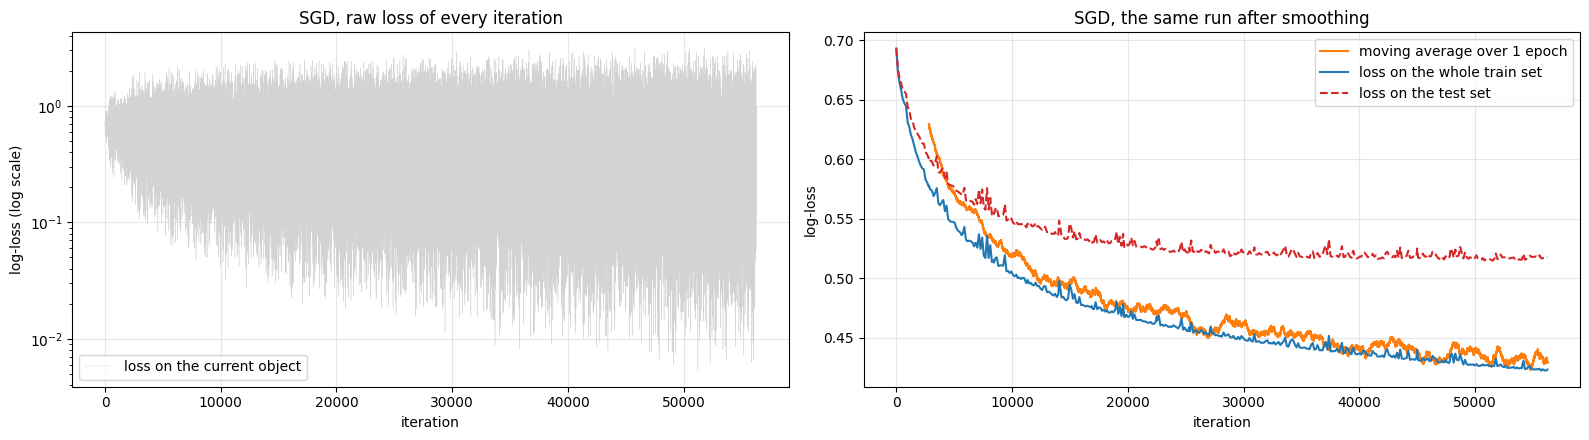

In [12]:
h = d_sgd['history']
raw = h['batch_loss']
window = m_train                                # moving average over one epoch
smooth = np.convolve(raw, np.ones(window) / window, mode='valid')

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].plot(np.arange(1, len(raw) + 1), raw, lw=0.3, color='lightgray', label='loss on the current object')
axes[0].set_yscale('log')
axes[0].set_title('SGD, raw loss of every iteration')
axes[0].set_xlabel('iteration'); axes[0].set_ylabel('log-loss (log scale)')
axes[0].legend(loc='lower left')

axes[1].plot(np.arange(window, len(raw) + 1), smooth, color='tab:orange', label='moving average over 1 epoch')
axes[1].plot(h['iteration'], h['train_loss'], color='tab:blue', label='loss on the whole train set')
axes[1].plot(h['iteration'], h['test_loss'], color='tab:red', ls='--', label='loss on the test set')
axes[1].set_title('SGD, the same run after smoothing')
axes[1].set_xlabel('iteration'); axes[1].set_ylabel('log-loss')
axes[1].legend()
plt.tight_layout(); plt.show()

The loss of one object jumps between 0.01 and 3, and there is no visible trend. With several learning rates on one plot like this, everything would merge into one gray cloud. The moving average and the loss on the whole train set show a smooth decrease with small noise, so in all SGD plots below I use the loss on the whole train set.

## 5. Task 3: Adam

g_t is the gradient at step t:

$$V_t = \beta_1 V_{t-1} + (1-\beta_1)\, g_t, \qquad S_t = \beta_2 S_{t-1} + (1-\beta_2)\, g_t^2$$

$$V_t^{corr} = \frac{V_t}{1-\beta_1^t}, \qquad S_t^{corr} = \frac{S_t}{1-\beta_2^t}, \qquad \theta_{t+1} = \theta_t - \frac{\eta}{\sqrt{S_t^{corr}} + \varepsilon}\, V_t^{corr}$$

The bias correction matters only in the first few dozen steps, while V_t and S_t are still close to zero. Parameters: β1 = 0.9, β2 = 0.999, ε = 1e-8, **lr = 0.001**.

The main run is full batch, 2000 iterations, like GD, so the only difference from GD is the update rule. Usually Adam is used with mini-batches, so I also run Adam with batches of 32 for 20 epochs, the same budget as SGD.

In [13]:
def optimize_adam(w, b, X, Y, num_epochs, learning_rate=0.001, beta1=0.9, beta2=0.999, epsilon=1e-8,
                  batch_size=None, seed=0, records_per_epoch=20, print_cost=False, eval_set=None):
    """Adam. batch_size=None means full batch: one iteration = one epoch, exactly like classic GD."""
    rng = np.random.default_rng(seed)
    m = X.shape[1]
    batch_size = batch_size or m
    iters_per_epoch = int(np.ceil(m / batch_size))
    record_every = max(1, iters_per_epoch // records_per_epoch)

    V_w, S_w = np.zeros_like(w), np.zeros_like(w)     # moving averages of gradients and squared gradients
    V_b, S_b = 0., 0.

    history = new_history()
    record(history, 0, 0, w, b, X, Y, eval_set)

    t = 0
    for epoch in range(num_epochs):
        order = rng.permutation(m) if batch_size < m else np.arange(m)
        for start in range(0, m, batch_size):
            idx = order[start:start + batch_size]
            grads, _ = propagate(w, b, X[:, idx], Y[:, idx])
            dw, db = grads["dw"], grads["db"]
            t += 1

            V_w = beta1 * V_w + (1 - beta1) * dw
            S_w = beta2 * S_w + (1 - beta2) * dw ** 2
            V_b = beta1 * V_b + (1 - beta1) * db
            S_b = beta2 * S_b + (1 - beta2) * db ** 2

            # bias correction: at the start V and S are biased towards 0
            V_w_corr, S_w_corr = V_w / (1 - beta1 ** t), S_w / (1 - beta2 ** t)
            V_b_corr, S_b_corr = V_b / (1 - beta1 ** t), S_b / (1 - beta2 ** t)

            w = w - learning_rate * V_w_corr / (np.sqrt(S_w_corr) + epsilon)
            b = b - learning_rate * V_b_corr / (np.sqrt(S_b_corr) + epsilon)

            if t % record_every == 0 or start + batch_size >= m:
                record(history, t, t / iters_per_epoch, w, b, X, Y, eval_set)

        if print_cost and (epoch + 1) % 500 == 0:
            print(f"epoch {epoch + 1}: train loss {history['train_loss'][-1]:.5f}")

    return {"w": w, "b": b}, grads, history

In [14]:
d_adam = model(train_set_x, train_set_y, test_set_x, test_set_y, optimizer="adam",
               learning_rate=0.001, num_epochs=2000, print_cost=True)
d_adam_mb = model(train_set_x, train_set_y, test_set_x, test_set_y, optimizer="adam",
                  learning_rate=0.001, num_epochs=20, batch_size=32)

epoch 500: train loss 0.36274
epoch 1000: train loss 0.30836
epoch 1500: train loss 0.27653
epoch 2000: train loss 0.25360
adam, lr = 0.001: train accuracy 0.9012, test accuracy 0.7537, test log-loss 0.6996 (7.7 s)
adam, lr = 0.001: train accuracy 0.8304, test accuracy 0.7569, test log-loss 0.5153 (0.5 s)


### 5.1. Comparison of GD, SGD and Adam

Besides accuracy, the table shows how many epochs (passes over train) each method needs to get the train loss down to 0.45. One GD iteration is a whole epoch, and one SGD iteration is 1 / 2813 of an epoch, so it is easier to compare speed in epochs than in iterations.

In [15]:
def epochs_to_reach(history, level):
    hit = np.flatnonzero(history['train_loss'] <= level)
    return history['epoch'][hit[0]] if len(hit) else np.nan


runs = {'GD, lr 0.1, 2000 it.': [d_gd],
        'SGD, lr 0.001, 20 ep. (mean of 5 seeds)': sgd_runs,
        'Adam full batch, lr 0.001, 2000 it.': [d_adam],
        'Adam batch 32, lr 0.001, 20 ep.': [d_adam_mb]}
rows = {}
for name, group in runs.items():
    h = group[0]['history']
    rows[name] = {'iterations': len(h['batch_loss']) if 'batch_loss' in h else h['iteration'][-1],
                  'epochs': h['epoch'][-1],
                  'train loss': np.mean([r['train_loss'] for r in group]),
                  'train acc': np.mean([r['train_acc'] for r in group]),
                  'test acc': np.mean([r['test_acc'] for r in group]),
                  'test log-loss': np.mean([r['test_loss'] for r in group]),
                  'epochs to train loss 0.45': np.mean([epochs_to_reach(r['history'], 0.45) for r in group])}
comparison = pd.DataFrame(rows).T
display(comparison.round(4))

n_test = test_set_y.shape[1]
se = np.sqrt(0.75 * 0.25 / n_test)
print(f'standard error of test accuracy near 0.75 with {n_test} test objects: {se:.4f} '
      f'(95% interval about ±{1.96 * se:.3f})')

,iterations,epochs,train loss,train acc,test acc,test log-loss,epochs to train loss 0.45
"GD, lr 0.1, 2000 it.",2000.0,2000.0,0.3729,0.8343,0.7559,0.5281,290.0000
"SGD, lr 0.001, 20 ep. (mean of 5 seeds)",56260.0,20.0,0.4231,0.8149,0.7446,0.5166,10.4316
"Adam full batch, lr 0.001, 2000 it.",2000.0,2000.0,0.2536,0.9012,0.7537,0.6996,174.0000
"Adam batch 32, lr 0.001, 20 ep.",1760.0,20.0,0.3939,0.8304,0.7569,0.5153,8.3636


standard error of test accuracy near 0.75 with 938 test objects: 0.0141 (95% interval about ±0.028)


- Accuracy: GD 0.756, SGD 0.745, Adam 0.754, mini-batch Adam 0.757. With 938 test objects the 95% interval for accuracy around 0.75 is about ±0.028, so all optimizers give the same quality.
- Speed in epochs: to reach train loss 0.45, GD needs 290 epochs, full batch Adam 174, SGD about 10 and mini-batch Adam about 8. Stochastic methods make many updates per epoch (2813 for SGD, 88 for batches of 32, 1 for GD). In seconds it is different: my Python loop has overhead on every single-object step, so here SGD is not faster than GD (about 1 s vs 0.4 s to reach 0.45). Mini-batches of 32 remove most of this overhead.
- Adam vs GD with the same 2000 full batch iterations: Adam gets a much lower train loss (0.254 vs 0.373, train accuracy 0.90 vs 0.83), because it scales the step for every weight separately, and weights with small gradients (for example rare binary descriptors) also move. On this data it means faster overfitting: test log-loss 0.70 vs 0.53 for GD. The lowest test loss of Adam was 0.533 at iteration 305, after that it only grew.

So the optimizer mostly changes how fast we get to the minimum. Test accuracy depends mostly on when we stop.

## 6. Task 4: learning curves of GD, SGD and Adam

The first three plots are loss vs iteration for each method (train solid, test dashed). The number of iterations is different (2000 for GD and Adam, 56 260 for SGD), so on the last plot all methods are on one axis, epochs in log scale.

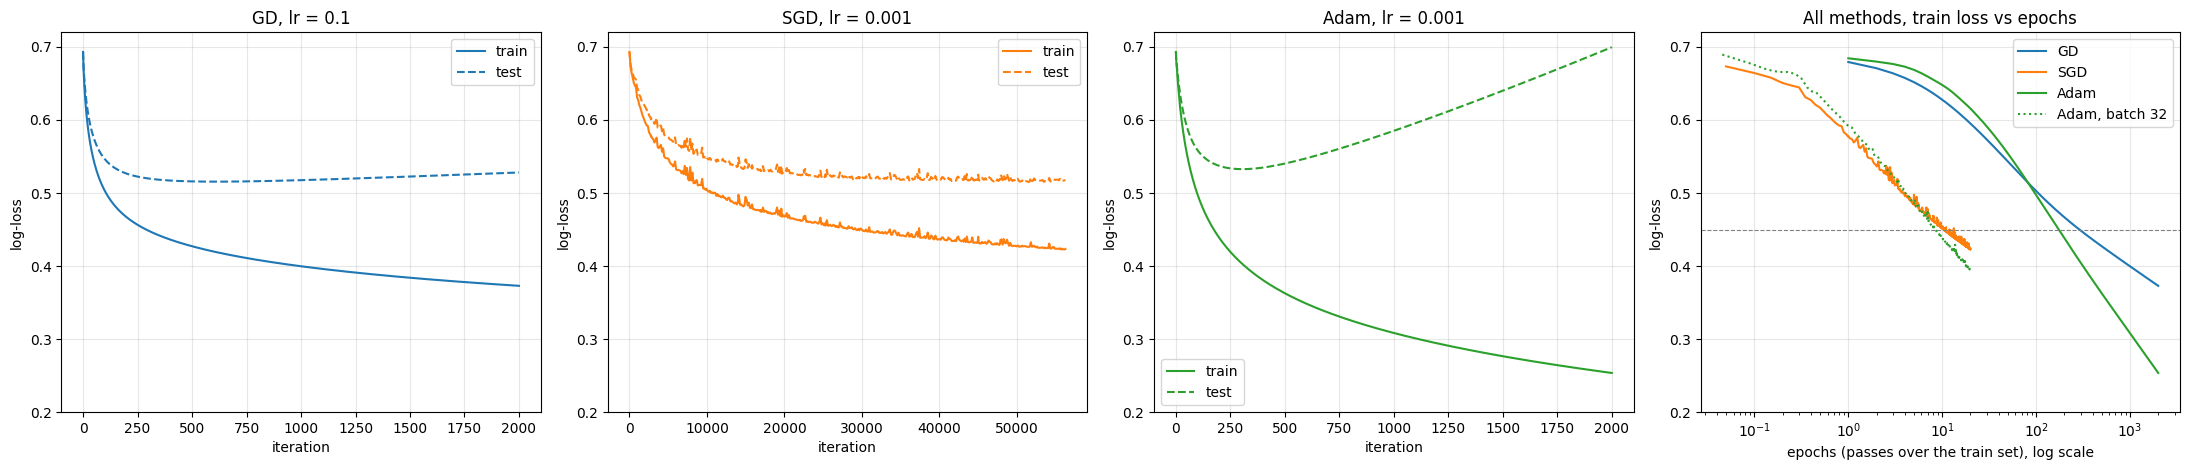

In [16]:
curves = [('GD, lr = 0.1', d_gd['history'], 'tab:blue', '-'),
          ('SGD, lr = 0.001', d_sgd['history'], 'tab:orange', '-'),
          ('Adam, lr = 0.001', d_adam['history'], 'tab:green', '-')]

fig, axes = plt.subplots(1, 4, figsize=(22, 4.8))
for ax, (name, h, color, _) in zip(axes[:3], curves):
    ax.plot(h['iteration'], h['train_loss'], color=color, label='train')
    ax.plot(h['iteration'], h['test_loss'], color=color, ls='--', label='test')
    ax.set_title(name)
    ax.set_xlabel('iteration'); ax.set_ylabel('log-loss'); ax.set_ylim(0.2, 0.72)
    ax.legend()

for name, h, color, ls in curves + [('Adam, batch 32', d_adam_mb['history'], 'tab:green', ':')]:
    pos = h['epoch'] > 0
    axes[3].plot(h['epoch'][pos], h['train_loss'][pos], color=color, ls=ls, label=name.split(',')[0] + (', batch 32' if 'batch' in name else ''))
axes[3].axhline(0.45, color='gray', lw=0.8, ls='--')
axes[3].set_xscale('log'); axes[3].set_ylim(0.2, 0.72)
axes[3].set_title('All methods, train loss vs epochs')
axes[3].set_xlabel('epochs (passes over the train set), log scale'); axes[3].set_ylabel('log-loss')
axes[3].legend()
plt.tight_layout(); plt.show()

- GD goes down smoothly, as expected with a step below 2 / L. The test loss is lowest around iteration 600 and then slowly grows while the train loss keeps falling, so overfitting starts there.
- SGD has the same shape with small noise. With lr = 0.001 and 20 epochs it has not started to overfit yet, the test loss is still flat.
- Adam has the steepest train curve. Its test loss has a clear minimum around iteration 300 and then grows quickly.
- On the epoch axis SGD and mini-batch Adam are more than 10 times ahead. Full batch Adam is a bit slower than GD for the first ~80 epochs (with lr = 0.001 each weight moves at most ~0.001 per step, while GD moves by 0.1 × gradient), then it overtakes GD.

## 7. Task 5: different learning rates

Five values for each optimizer, from too small to too large. The grids are different because lr means different things:
- in GD the step is lr times the gradient averaged over 2813 objects, and the limit is 2 / L = 0.14;
- in SGD the gradient of one object is larger and noisier, so the working values are 10-100 times smaller;
- in Adam each weight moves by about lr per step, whatever the gradient is.

The budgets are the same: 2000 iterations for GD and full batch Adam, 20 epochs for SGD. SGD is run with 3 seeds, and the plots show the mean curve and a band between the best and the worst seed.

In [17]:
LR_GRID = {'gd':   [0.001, 0.01, 0.1, 0.3, 1.0],
           'sgd':  [0.0001, 0.001, 0.003, 0.01, 0.1],
           'adam': [0.0001, 0.001, 0.01, 0.1, 1.0]}
EPOCHS = {'gd': 2000, 'sgd': 20, 'adam': 2000}
SEEDS = {'gd': [None], 'sgd': [0, 1, 2], 'adam': [0]}      # GD and full batch Adam do not use randomness

sweep = {}
start = time.time()
for opt, lrs in LR_GRID.items():
    for lr in lrs:
        sweep[opt, lr] = [model(train_set_x, train_set_y, test_set_x, test_set_y, optimizer=opt, learning_rate=lr,
                                num_epochs=EPOCHS[opt], verbose=False, **({} if s is None else {'seed': s}))
                          for s in SEEDS[opt]]
print(f'{len(sweep)} settings, {sum(len(v) for v in sweep.values())} runs, {time.time() - start:.0f} s')

15 settings, 25 runs, 69 s


Each column is one optimizer, each learning rate has its own color (blue is the smallest, purple the largest).
- Top row: train loss over the whole range, log scale. The unstable runs are visible here.
- Middle row: train loss zoomed in, linear scale, so the working learning rates don't merge. Runs that are unstable at the end (final train loss above 0.9 · ln 2, where ln 2 is the starting value) are only drawn in the top row, otherwise their spikes would cover this panel.
- Bottom row: test loss, zoomed in the same way.

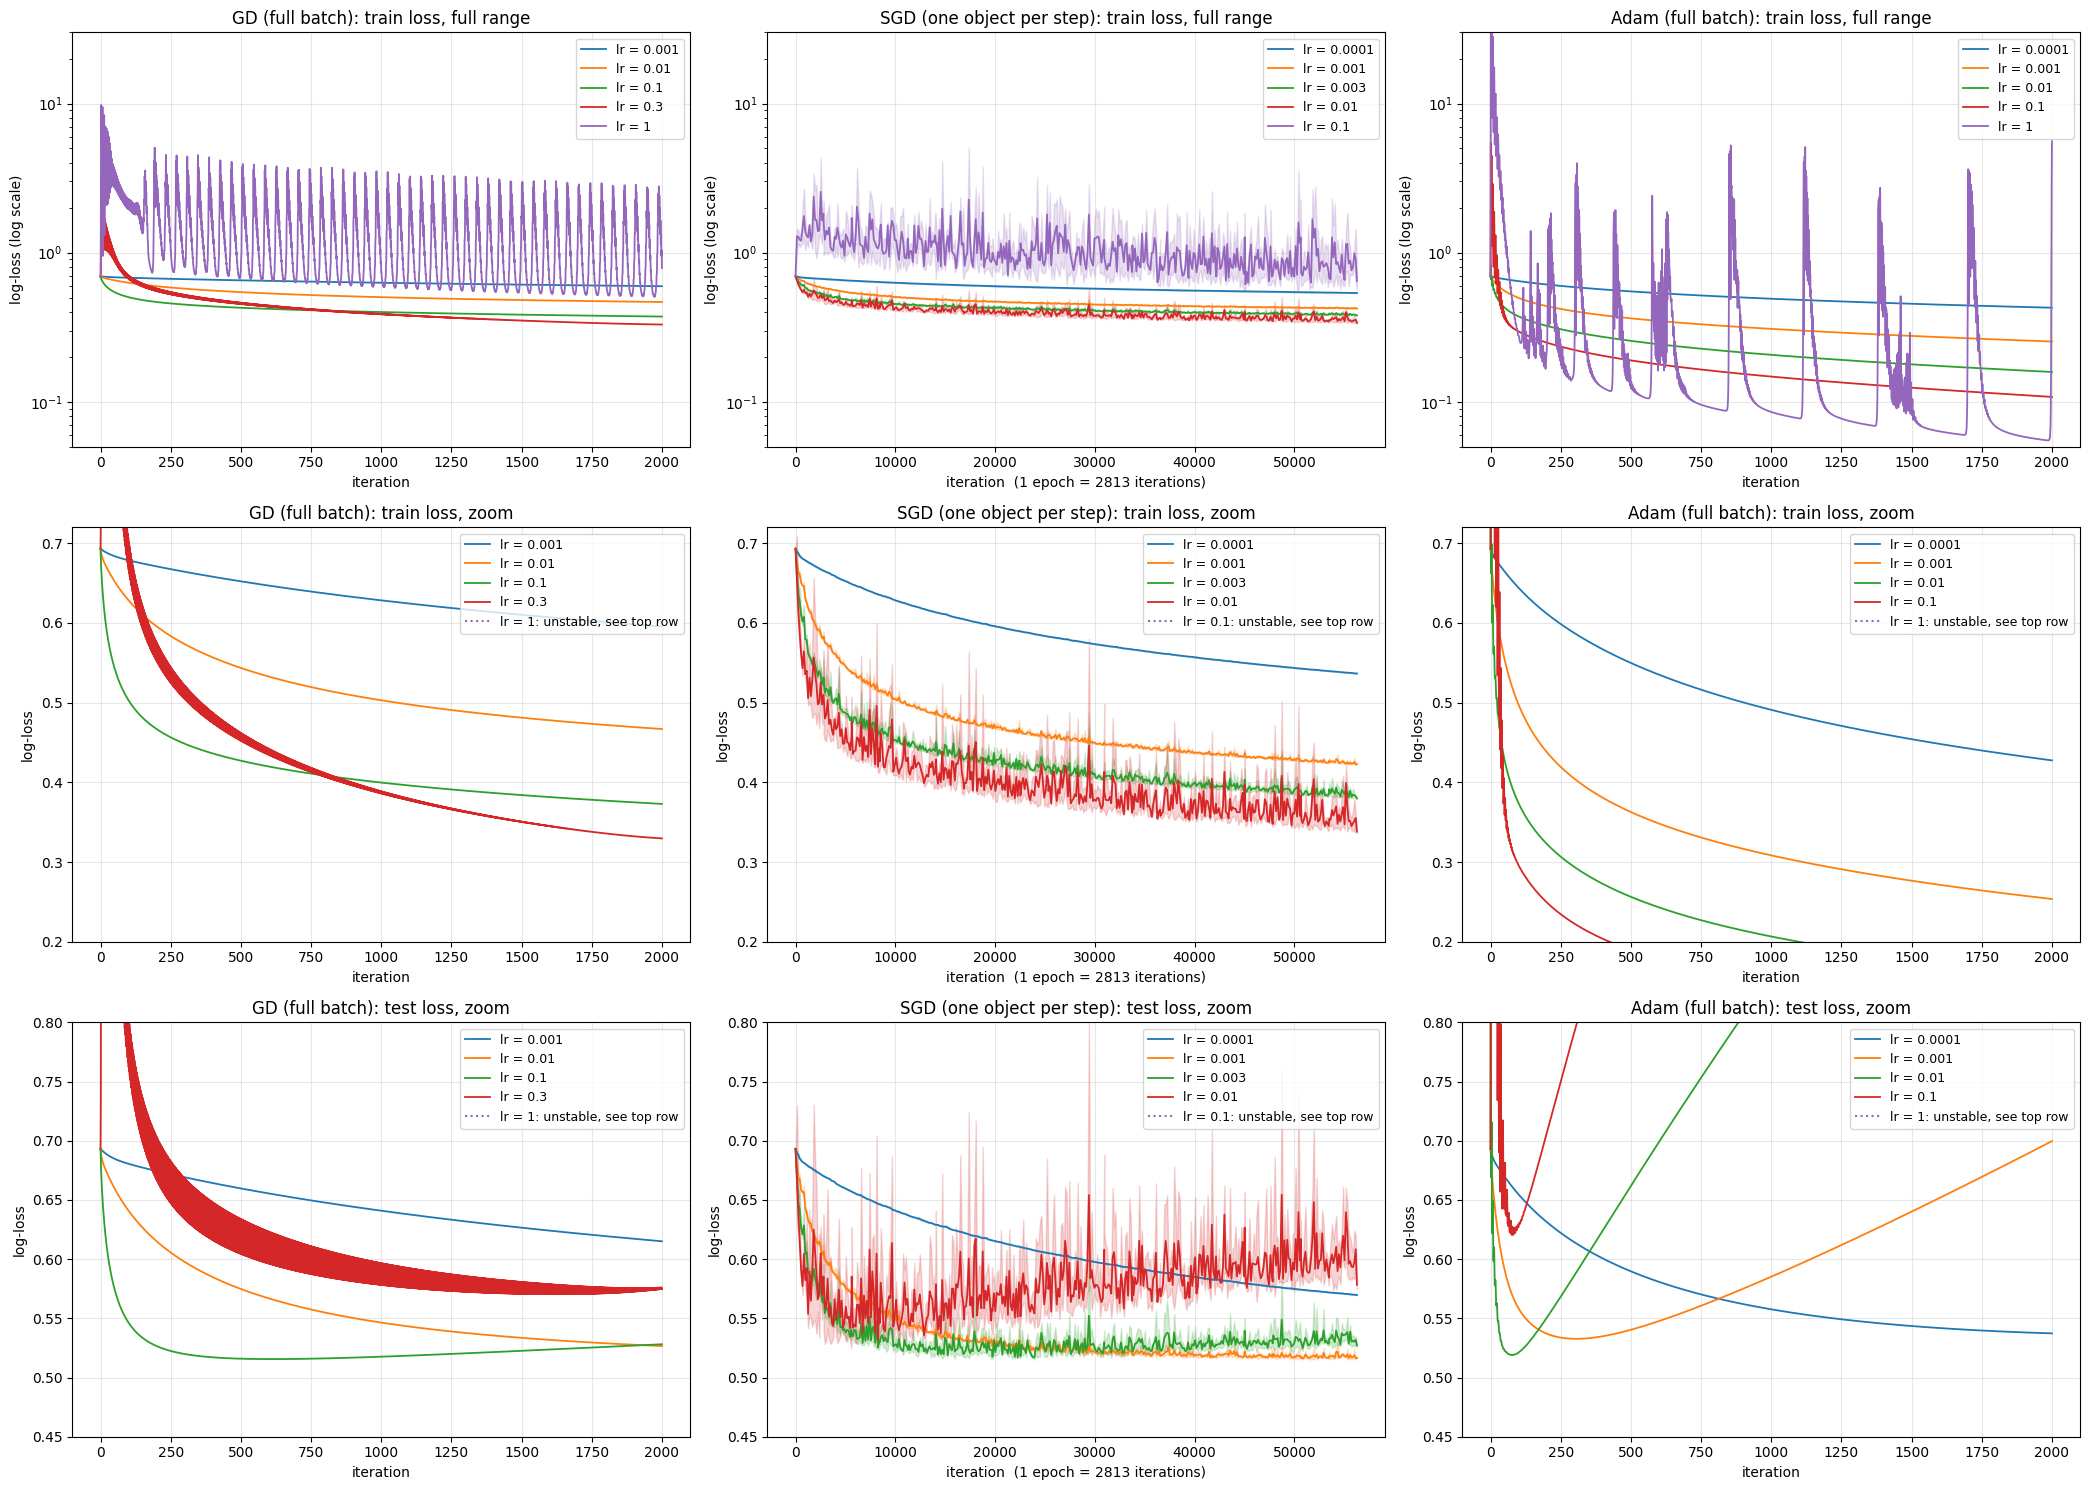

In [18]:
TITLES = {'gd': 'GD (full batch)', 'sgd': 'SGD (one object per step)', 'adam': 'Adam (full batch)'}
LR_COLORS = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']    # from the smallest lr to the largest
PANELS = [('train_loss', 'train loss, full range', 'log', (0.05, 30)),
          ('train_loss', 'train loss, zoom', 'linear', (0.2, 0.72)),
          ('test_loss', 'test loss, zoom', 'linear', (0.45, 0.8))]


def unstable(runs_lr):
    return np.mean([r['train_loss'] for r in runs_lr]) > 0.9 * np.log(2)


fig, axes = plt.subplots(3, 3, figsize=(21, 15))
for j, (opt, lrs) in enumerate(LR_GRID.items()):
    for lr, color in zip(lrs, LR_COLORS):
        runs_lr = sweep[opt, lr]
        it = runs_lr[0]['history']['iteration']
        for i, (key, _, _, _) in enumerate(PANELS):
            ax = axes[i, j]
            if i > 0 and unstable(runs_lr):
                ax.plot([], [], color=color, ls=':', label=f'lr = {lr:g}: unstable, see top row')
                continue
            curves_lr = np.array([r['history'][key] for r in runs_lr])
            ax.plot(it, curves_lr.mean(axis=0), color=color, lw=1.3, label=f'lr = {lr:g}')
            if len(runs_lr) > 1:                # SGD: band between the best and the worst seed
                ax.fill_between(it, curves_lr.min(axis=0), curves_lr.max(axis=0), color=color, alpha=0.2)
    for i, (_, name, scale, ylim) in enumerate(PANELS):
        ax = axes[i, j]
        ax.set_yscale(scale); ax.set_ylim(*ylim)
        ax.set_title(f'{TITLES[opt]}: {name}')
        ax.set_xlabel('iteration' + (f'  (1 epoch = {m_train} iterations)' if opt == 'sgd' else ''))
        ax.set_ylabel('log-loss' + (' (log scale)' if scale == 'log' else ''))
        ax.legend(fontsize=9, loc='upper right')
plt.tight_layout(); plt.show()

SGD curves are the noisiest, so here they are again, one plot per learning rate (seed 0): the 1-epoch moving average of the per-step loss, the loss on the whole train set and the test loss.

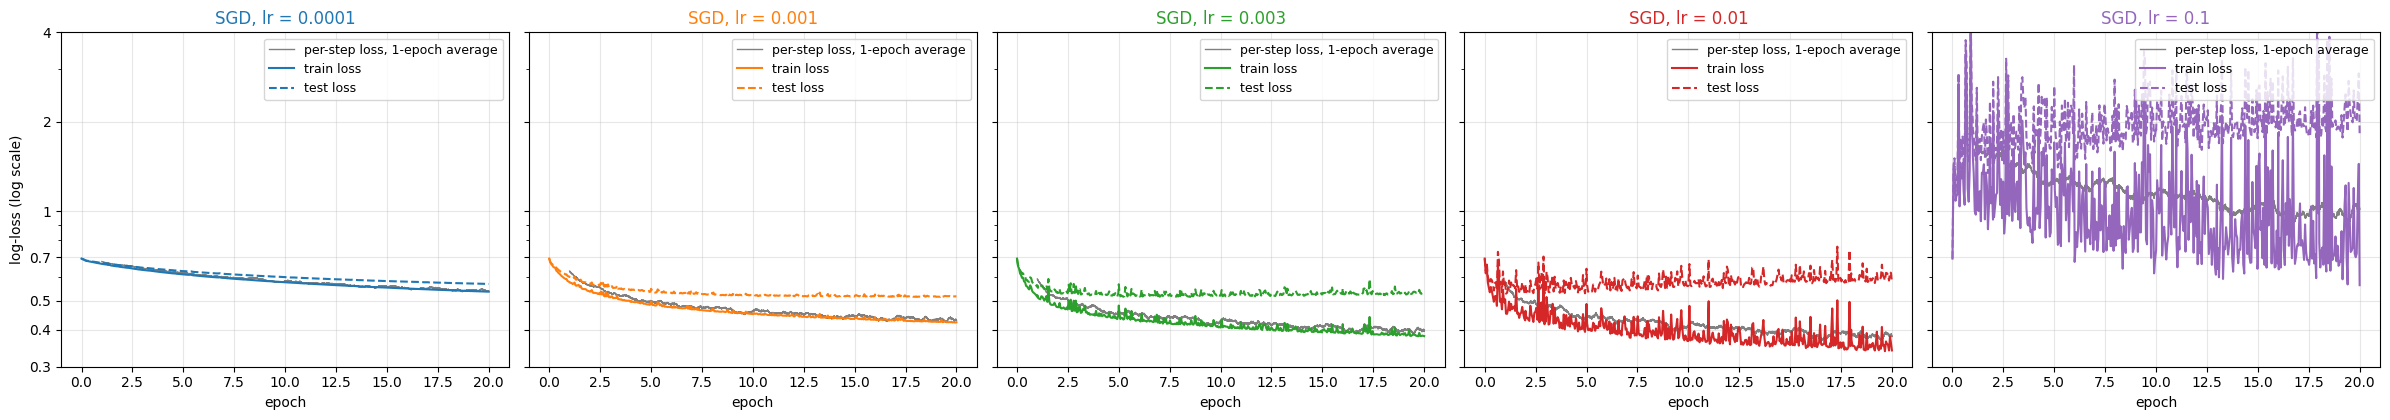

In [19]:
lrs = LR_GRID['sgd']
fig, axes = plt.subplots(1, len(lrs), figsize=(24, 4.3), sharey=True)
for ax, lr, color in zip(axes, lrs, LR_COLORS):
    h = sweep['sgd', lr][0]['history']
    smooth = np.convolve(h['batch_loss'], np.ones(m_train) / m_train, mode='valid')
    ax.plot(np.arange(m_train, len(h['batch_loss']) + 1) / m_train, smooth, color='gray', lw=1,
            label='per-step loss, 1-epoch average')
    ax.plot(h['epoch'], h['train_loss'], color=color, label='train loss')
    ax.plot(h['epoch'], h['test_loss'], color=color, ls='--', label='test loss')
    ax.set_title(f'SGD, lr = {lr:g}', color=color)
    ax.set_xlabel('epoch'); ax.set_yscale('log'); ax.set_ylim(0.3, 4)
    ax.set_yticks([0.3, 0.4, 0.5, 0.7, 1, 2, 4]); ax.set_yticklabels(['0.3', '0.4', '0.5', '0.7', '1', '2', '4'])
    ax.legend(fontsize=9, loc='upper right')
axes[0].set_ylabel('log-loss (log scale)')
plt.tight_layout(); plt.show()

In [20]:
rows = []
for (opt, lr), runs_lr in sweep.items():
    h = runs_lr[0]['history']
    best = int(np.argmin(h['test_loss']))
    rows.append({'optimizer': TITLES[opt].split()[0], 'lr': lr,
                 'train loss': np.mean([r['train_loss'] for r in runs_lr]),
                 'train acc': np.mean([r['train_acc'] for r in runs_lr]),
                 'test acc': np.mean([r['test_acc'] for r in runs_lr]),
                 'test log-loss': np.mean([r['test_loss'] for r in runs_lr]),
                 'lowest test log-loss on the way': h['test_loss'][best],
                 'reached at epoch': h['epoch'][best]})
lr_table = pd.DataFrame(rows).set_index(['optimizer', 'lr'])
display(lr_table.round(4))
print('the last two columns are taken from the first run (for SGD: seed 0), the others are averaged over the seeds')

train loss  train acc  test acc  test log-loss  \
optimizer lr                                                       
GD        0.0010      0.5957     0.7220    0.6930         0.6151   
          0.0100      0.4669     0.7938    0.7324         0.5266   
          0.1000      0.3729     0.8343    0.7559         0.5281   
          0.3000      0.3297     0.8599    0.7548         0.5747   
          1.0000      0.7888     0.7991    0.7036         1.5721   
SGD       0.0001      0.5366     0.7597    0.7324         0.5697   
          0.0010      0.4229     0.8146    0.7416         0.5165   
          0.0030      0.3799     0.8337    0.7552         0.5271   
          0.0100      0.3382     0.8519    0.7548         0.5783   
          0.1000      0.6459     0.8351    0.7217         1.9127   
Adam      0.0001      0.4276     0.8230    0.7431         0.5373   
          0.0010      0.2536     0.9012    0.7537         0.6996   
          0.0100      0.1585     0.9485    0.7303         1.1629   
          0.1000      0.1078     0.9694    0.7068         1.8926   
          1.0000      5.5854     0.6665    0.6045        12.5872   

                  lowest test log-loss on the way  reached at epoch  
optimizer lr                                                         
GD        0.0010                           0.6151         2000.0000  
          0.0100                           0.5266         2000.0000  
          0.1000                           0.5156          613.0000  
          0.3000                           0.5704         1624.0000  
          1.0000                           0.6931            0.0000  
SGD       0.0001                           0.5696           20.0000  
          0.0010                           0.5149           18.3150  
          0.0030                           0.5151            8.5105  
          0.0100                           0.5248            1.9908  
          0.1000                           0.6931            0.0000  
Adam      0.0001                           0.5373         2000.0000  
          0.0010                           0.5327          305.0000  
          0.0100                           0.5190           80.0000  
          0.1000                           0.6204           76.0000  
          1.0000                           0.6931            0.0000

the last two columns are taken from the first run (for SGD: seed 0), the others are averaged over the seeds


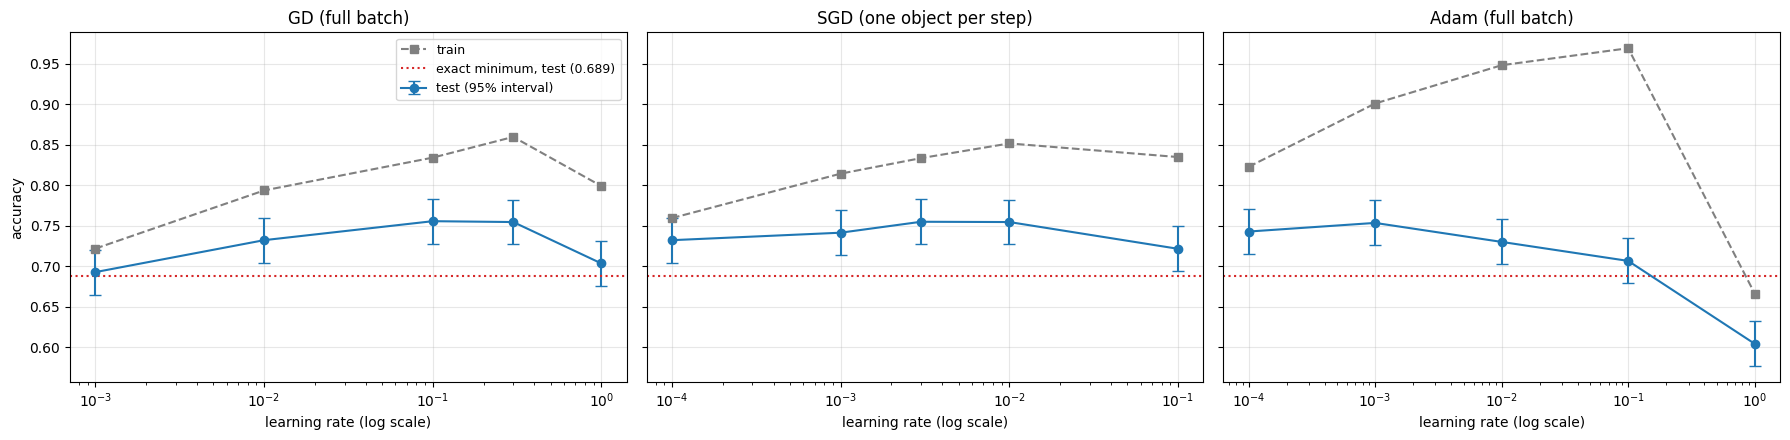

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, opt in zip(axes, LR_GRID):
    t = lr_table.xs(TITLES[opt].split()[0])
    ax.errorbar(t.index, t['test acc'], yerr=1.96 * se, fmt='o-', capsize=4, label='test (95% interval)')
    ax.plot(t.index, t['train acc'], 's--', color='gray', label='train')
    ax.axhline(ref_test_acc, color='tab:red', ls=':', label=f'exact minimum, test ({ref_test_acc:.3f})')
    ax.set_xscale('log'); ax.set_title(TITLES[opt])
    ax.set_xlabel('learning rate (log scale)')
axes[0].set_ylabel('accuracy'); axes[0].legend(fontsize=9)
plt.tight_layout(); plt.show()

**How the learning rate affects accuracy.** For all three optimizers test accuracy vs lr looks like an upside-down U, but on the right side they fail for different reasons.

- Too small (GD 0.001, SGD 0.0001, Adam 0.0001): the weights don't get far from zero within the budget. The train loss is still 0.43-0.60 and still falling at the end, and the lowest test loss is at the last iteration. The model underfits, test accuracy is 0.69-0.74.
- Working range (GD 0.1-0.3, SGD 0.003-0.01, Adam 0.001): test accuracy 0.754-0.756 for all three, the differences are much smaller than the ±0.028 noise.
- Too large for GD and SGD: the steps jump over the minimum. GD with lr = 1 is far above 2 / L = 0.14. The train loss jumps up to almost 10 in the first iterations and then keeps jumping between 0.5 and 3-5 until the end, test accuracy is 0.704. lr = 0.3 is also above the limit: the train loss first jumps up to 2.2 and zigzags for about 500 iterations. Then it calms down, because when the predictions move away from 0.5 the real curvature is smaller than L (L assumes the worst case σ' = 1/4). Small oscillations stay and show up as a thick band on the test loss (0.575 vs 0.528 for lr = 0.1), though the accuracy is the same. SGD with lr = 0.1 almost never gets below train loss 0.6 (median about 0.9), the noise of single-object steps is bigger than the progress. Test accuracy 0.722.
- Too large for Adam: first overfitting, then instability. Adam normalizes the steps, so it is stable up to lr = 0.1, but with a large lr it quickly gets to the overfitted minimum. With lr = 0.01 train accuracy is 0.95 and test 0.730, with lr = 0.1 it is 0.97 and 0.707, close to the exact minimum (0.689). With lr = 1 each weight jumps by about 1 per step. The train loss falls very low and then explodes again, many times, and the run ends on such a spike: train loss 5.6, test accuracy 0.60.
- The lowest test loss during training (table) is almost the same (0.515-0.537) for all learning rates that train smoothly and are large enough to reach the good region. The exceptions are the too small ones (GD 0.001: 0.615, SGD 0.0001: 0.570, both still falling at the end), GD with lr = 0.3 (0.570, oscillations) and Adam with lr = 0.1 (0.620, a big jump at the start). What changes is when it is reached: epoch 2 for SGD with lr = 0.01, epoch 18 with lr = 0.001, iteration 80 for Adam with lr = 0.01 and iteration 305 with lr = 0.001. So the learning rate mostly decides how fast the model passes the good point and whether it is still near it when training stops.

## 8. Task 6: conclusions

1. Logistic regression with my numpy GD, SGD and Adam gives about **0.75 test accuracy** (GD 0.756, SGD 0.745 ± 0.006, Adam 0.754, mini-batch Adam 0.757). With 938 test objects these differences are not significant. The optimizer doesn't change the model, only the way to the weights.
2. In passes over the data stochastic methods are much faster: about 10 epochs for SGD and 8 for Adam with batches of 32 to reach train loss 0.45, against 290 for GD and 174 for full batch Adam. Mini-batches are the best option in practice: with batches of 32 there are 88 updates per epoch instead of 2813, but they are less noisy and vectorized, and here mini-batch Adam needed even fewer epochs than SGD.
3. With the same full batch iterations Adam lowers the train loss much faster than GD (0.254 vs 0.373 after 2000 iterations), because the step is adapted for every weight. But on this data it also starts to overfit sooner.
4. The learning rate matters more than anything else. Too small gives underfitting within the budget. Too large gives oscillations for GD and SGD (the limit 2 / L = 0.14 for GD agrees with the experiment: 0.3 already oscillates, 1 never settles), and fast overfitting and then instability for Adam. Accuracy vs lr is an upside-down U for every optimizer, the best values are GD 0.1-0.3, SGD 0.003-0.01, Adam about 0.001.
5. This dataset has 1776 features for 2813 training objects, so the train set is almost linearly separable and the exact minimum without regularization overfits (0.689 test accuracy vs 0.75 for the stopped models). Here the number of iterations together with the learning rate works as regularization. In a real task I would choose the stopping point on a validation part (early stopping) or add L2 instead of using a fixed budget.
6. For SGD the learning curve should be the loss on the whole train set (or a moving average), not the loss of single objects, otherwise the curves for different learning rates can't be told apart. Unstable runs are easier to see in log scale, and a separate zoomed panel keeps them from hiding the other curves.